In [1]:
import sys
sys.path.append("../src")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from features import FEATURES, CAT_COLS
from metrics import evaluate

feat = pd.read_parquet("../data/processed/features.parquet")

tr = feat[feat.split == "train"]
va = feat[feat.split == "val"]

X_tr, y_tr = tr[FEATURES], tr["isFraud"]
X_va, y_va = va[FEATURES], va["isFraud"]

print(X_tr.shape, X_va.shape)
print("train fraud rate:", y_tr.mean().round(4), "| val fraud rate:", y_va.mean().round(4))

(220806, 62) (91768, 62)
train fraud rate: 0.0311 | val fraud rate: 0.0403


In [2]:
rng = np.random.default_rng(0)
dumb_scores = rng.random(len(y_va))

results = {"random guess": evaluate(y_va, dumb_scores)}
results

{'random guess': {'pr_auc': 0.0408, 'roc_auc': 0.5051, 'recall@80%prec': 0.0}}

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

num_cols = [c for c in FEATURES if c not in CAT_COLS]

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=200), CAT_COLS),
])

lr = Pipeline([("prep", pre),
               ("clf", LogisticRegression(max_iter=500, class_weight="balanced"))])


def as_text(X):
    X = X.copy()
    X[CAT_COLS] = X[CAT_COLS].astype(str)
    return X


lr.fit(as_text(X_tr), y_tr)
lr_scores = lr.predict_proba(as_text(X_va))[:, 1]

results["logistic regression"] = evaluate(y_va, lr_scores)
results

{'random guess': {'pr_auc': 0.0408, 'roc_auc': 0.5051, 'recall@80%prec': 0.0},
 'logistic regression': {'pr_auc': 0.214,
  'roc_auc': 0.7977,
  'recall@80%prec': 0.0208}}

In [4]:
import lightgbm as lgb

lgbm = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=100,
    subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)

lgbm.fit(
    X_tr, y_tr,
    eval_set=[(X_va, y_va)],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)],
)

lgbm_scores = lgbm.predict_proba(X_va)[:, 1]
results["lightgbm"] = evaluate(y_va, lgbm_scores)
print("best round:", lgbm.best_iteration_)

c:\Users\ASUS\OneDrive\Desktop\data analysis\fraud-monitoring\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's average_precision: 0.594352	valid_0's binary_logloss: 0.0978596
[200]	valid_0's average_precision: 0.611262	valid_0's binary_logloss: 0.0950149
[300]	valid_0's average_precision: 0.616145	valid_0's binary_logloss: 0.0948025
Early stopping, best iteration is:
[293]	valid_0's average_precision: 0.616024	valid_0's binary_logloss: 0.0947757
best round: 293


In [5]:
table = pd.DataFrame(results).T
table

,pr_auc,roc_auc,recall@80%prec
random guess,0.0408,0.5051,0.0000
logistic regression,0.2140,0.7977,0.0208
lightgbm,0.6160,0.9175,0.4216


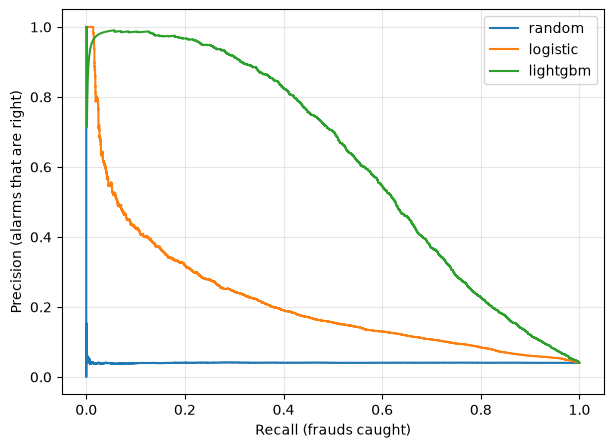

In [6]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(7, 5))
for name, s in [("random", dumb_scores), ("logistic", lr_scores), ("lightgbm", lgbm_scores)]:
    p, r, _ = precision_recall_curve(y_va, s)
    plt.plot(r, p, label=name)
plt.xlabel("Recall (frauds caught)")
plt.ylabel("Precision (alarms that are right)")
plt.legend(); plt.grid(alpha=.3); plt.show()

In [7]:
imp = pd.Series(lgbm.booster_.feature_importance(importance_type="gain"),
                index=FEATURES).sort_values(ascending=False)
(imp / imp.sum()).head(15).round(3)

C13               0.081
C1                0.078
card2             0.045
card1             0.044
addr1             0.040
C4                0.039
D2                0.039
C12               0.036
R_emaildomain     0.035
TransactionAmt    0.032
C14               0.032
D3                0.029
D15               0.028
n_prior_txn       0.024
C2                0.023
dtype: float64

In [8]:
imp = pd.Series(lgbm.booster_.feature_importance(importance_type="gain"),
                index=FEATURES).sort_values(ascending=False)
(imp / imp.sum()).head(15).round(3)

C13               0.081
C1                0.078
card2             0.045
card1             0.044
addr1             0.040
C4                0.039
D2                0.039
C12               0.036
R_emaildomain     0.035
TransactionAmt    0.032
C14               0.032
D3                0.029
D15               0.028
n_prior_txn       0.024
C2                0.023
dtype: float64

LightGBM reaches a validation PR-AUC of 0.616, about 15 times the random baseline (0.041) and about 3 times logistic regression (0.214). At 80% precision it catches about 42% of fraud. The most important features are anonymised count columns (C13, C1) and card and address identifiers (card1, card2, addr1). Of my engineered features, only n_prior_txn appears in the top 15. Importance is gain-based and does not imply causation.

In [10]:
joblib.dump(lgbm, "../models/lgbm_day3.joblib")
table.to_csv("../docs/day3_results.csv")